# 01 — Exploratory Data Analysis: Bank Card Fraud Detection

**Goal:** Understand what is in the data, find quality issues, characterize fraud imbalance, and identify candidate signals before training CatBoost.

**Data sources:** `data/train.csv`, `data/test.csv`, `data/data_dictionary.md`.

**Competition rules to remember:** ROC AUC is the scoring metric; test labels are unavailable; the test time period follows train; label-free aggregates over train + test are permitted, but `is_fraud` must **never** be used to build test features. Avoid using future **labels** during validation.

Run cells in order with **Shift + Enter**. After each section, read the observations and try to explain *why* the result matters.

## 1. Set up Python and find the project root

- `Path.cwd()` returns the notebook's current working directory.
- VS Code may use the repository root **or** the `notebooks/` directory, so we handle both.
- `assert` stops early if the expected file path is wrong.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

current_directory = Path.cwd()
project_root = current_directory if (current_directory / "data" / "train.csv").exists() else current_directory.parent

data_directory = project_root / "data"
assert (data_directory / "train.csv").exists(), f"Cannot find train.csv in {data_directory}"
assert (data_directory / "test.csv").exists(), f"Cannot find test.csv in {data_directory}"

print("Working directory:", current_directory)
print("Project root:", project_root)
print("Pandas version:", pd.__version__)

Working directory: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost\notebooks
Project root: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost
Pandas version: 3.1.1


## 2. Load and preview the datasets

- `pd.read_csv()` loads a CSV into a **DataFrame** (a table with labeled columns).
- `.shape` gives `(number_of_rows, number_of_columns)`.
- `.head()` shows the first few rows. Loading timestamps as strings first lets us examine their format before conversion.

In [2]:
train = pd.read_csv(data_directory / "train.csv")
test = pd.read_csv(data_directory / "test.csv")

print("Train shape:", train.shape)
print("Test shape: ", test.shape)
print("Target in train:", "is_fraud" in train.columns)
print("Target in test: ", "is_fraud" in test.columns)

display(train.head(3))
display(test.head(3))

Train shape: (60197, 20)
Test shape:  (39803, 19)
Target in train: True
Target in test:  False


,transaction_id,timestamp,card_id,card_holder,customer_age,customer_home_country,account_age_days,amount,merchant_id,merchant_name,merchant_category,merchant_country,is_foreign_merchant,channel,card_present,device_id,ip_address,ip_country,is_foreign_ip,is_fraud
0,TXN_000001,2026-01-01 00:07:15,C03949,Frau Krystyna Fliegner MBA.,50,NL,682,171.70,M00042,Nogueira Sá e Filhos,gambling,NL,0,in_store,True,NaN,72.164.29.89,NL,0,0
1,TXN_000002,2026-01-01 00:34:05,C02996,Dipl.-Ing. Cemil Lübs,22,DE,842,248.09,M00532,Small-Anderson,travel,DE,0,recurring,False,NaN,12.5.250.227,DE,0,0
2,TXN_000003,2026-01-01 01:00:23,C06754,Scott Turner,53,IT,111,305.51,M00800,Kreusel,travel,IT,0,in_store,True,NaN,22.113.42.172,IT,0,0


,transaction_id,timestamp,card_id,card_holder,customer_age,customer_home_country,account_age_days,amount,merchant_id,merchant_name,merchant_category,merchant_country,is_foreign_merchant,channel,card_present,device_id,ip_address,ip_country,is_foreign_ip
0,TXN_060198,2/6/2026 0:07,C04865,Michèle Traore-Rossi,35,BR,289,87.13,M00853,de Man Groep,crypto,BR,0,in_store,True,NaN,153.238.103.239,BR,0
1,TXN_060199,2/6/2026 0:16,C02380,Íngrid Rivas,47,BR,883,30.10,M00504,Jesus Sales S.A.,retail,BR,0,recurring,False,NaN,180.181.139.159,BR,0
2,TXN_060200,2/6/2026 0:18,C05436,Jack Singh,44,US,107,8.60,M01580,Gough Ltd,pharmacy,US,0,online,False,D030436,181.41.30.11,US,0


## 3. Inspect data types and schema

- `.info()` lists feature types and counts of non-missing values.
- For CatBoost, we want to know which fields are numeric, categorical, timestamps, IDs, and the target.
- Do **not** assume an `object` column is already a datetime or useful numeric feature.

In [3]:
print("=== TRAIN INFORMATION ===")
train.info()
print("\n=== TEST INFORMATION ===")
test.info()

feature_columns = [column for column in train.columns if column != "is_fraud"]
print("\nAll train features present in test:", set(feature_columns) == set(test.columns))
print("Unique card IDs in training:", train["card_id"].nunique())
print("Unique merchant IDs in training:", train["merchant_id"].nunique())

=== TRAIN INFORMATION ===
<class 'pandas.DataFrame'>
RangeIndex: 60197 entries, 0 to 60196
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   transaction_id         60197 non-null  str    
 1   timestamp              60197 non-null  str    
 2   card_id                60197 non-null  str    
 3   card_holder            60197 non-null  str    
 4   customer_age           60197 non-null  int64  
 5   customer_home_country  60197 non-null  str    
 6   account_age_days       60197 non-null  int64  
 7   amount                 60197 non-null  float64
 8   merchant_id            60197 non-null  str    
 9   merchant_name          60197 non-null  str    
 10  merchant_category      60197 non-null  str    
 11  merchant_country       60197 non-null  str    
 12  is_foreign_merchant    60197 non-null  int64  
 13  channel                60197 non-null  str    
 14  card_present           60197 non-null  

## 4. Missing values: missing does not always mean bad data

- `.isna()` marks missing entries as `True`.
- `.sum()` counts them per column.
- For `device_id`, missing is **expected** for `in_store` and `recurring` transactions. We should preserve that meaning rather than fill it with a random device.

In [4]:
missing_summary = pd.DataFrame({
    "train_missing": train.isna().sum(),
    "train_missing_pct": 100 * train.isna().mean(),
    "test_missing": test.isna().sum(),
    "test_missing_pct": 100 * test.isna().mean(),
}).sort_values("train_missing", ascending=False)

display(missing_summary.round(2))

print("Device ID missingness by channel (train):")
display(pd.crosstab(train["channel"], train["device_id"].isna(),
                    rownames=["channel"], colnames=["device_id_missing"]))

,train_missing,train_missing_pct,test_missing,test_missing_pct
device_id,31403,52.17,20849.0,52.38
account_age_days,0,0.00,0.0,0.00
card_holder,0,0.00,0.0,0.00
amount,0,0.00,0.0,0.00
card_id,0,0.00,0.0,0.00
card_present,0,0.00,0.0,0.00
customer_age,0,0.00,0.0,0.00
channel,0,0.00,0.0,0.00
customer_home_country,0,0.00,0.0,0.00
ip_address,0,0.00,0.0,0.00


Device ID missingness by channel (train):


device_id_missing,False,True
channel,,
in_store,0,23951
online,28794,0
recurring,0,7452


## 5. Duplicates and transaction IDs

- `.duplicated()` checks repeated rows.
- A unique `transaction_id` should not repeat within one dataset or across train and test.
- IDs can be necessary for **submissions** without being meaningful features for learning.

In [5]:
print("Duplicate full rows — train:", train.duplicated().sum())
print("Duplicate full rows — test: ", test.duplicated().sum())
print("Duplicate IDs — train:", train["transaction_id"].duplicated().sum())
print("Duplicate IDs — test: ", test["transaction_id"].duplicated().sum())
print("IDs occurring in both splits:", len(set(train["transaction_id"]) & set(test["transaction_id"])))

Duplicate full rows — train: 0
Duplicate full rows — test:  0
Duplicate IDs — train: 0
Duplicate IDs — test:  0
IDs occurring in both splits: 0


## 6. Inspect class imbalance (training labels only)

- `.value_counts()` counts each class.
- `.value_counts(normalize=True)` gives proportions.
- We report the **fraud rate** and draw a bar chart.

**Important:** A model that always outputs `0` can have high accuracy here but be useless at detecting fraud. The competition uses **ROC AUC**, which measures ranking ability.

Class counts:
is_fraud
0    59398
1      799
Name: count, dtype: int64

Class proportions:
is_fraud
0    98.67%
1     1.33%
Name: proportion, dtype: str


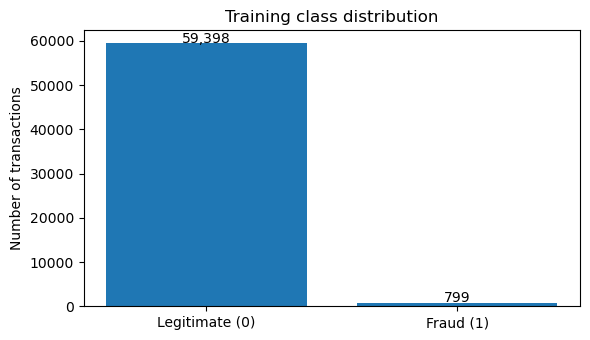

In [6]:
class_counts = train["is_fraud"].value_counts().sort_index()
class_proportions = train["is_fraud"].value_counts(normalize=True).sort_index()

print("Class counts:")
print(class_counts)
print("\nClass proportions:")
print((100 * class_proportions).round(2).astype(str) + "%")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(["Legitimate (0)", "Fraud (1)"], class_counts.values)
ax.set(title="Training class distribution", ylabel="Number of transactions")
for i, count in enumerate(class_counts.values):
    ax.text(i, count + 200, f"{count:,}", ha="center")
plt.tight_layout()
plt.show()

## 7. Parse dates correctly and compare periods

The train file uses `YYYY-MM-DD HH:MM:SS`. The test file is actually formatted `M/D/YYYY H:MM` in this upload, although the dictionary describes a different nominal format.

We parse each **explicitly** and verify nothing turned into `NaT` (missing datetime). The test data extends slightly into March 2.

In [7]:
train["timestamp"] = pd.to_datetime(train["timestamp"], format="%Y-%m-%d %H:%M:%S", errors="raise")
test["timestamp"] = pd.to_datetime(test["timestamp"], format="%m/%d/%Y %H:%M", errors="raise")

print("Training period:", train["timestamp"].min(), "to", train["timestamp"].max())
print("Test period:    ", test["timestamp"].min(), "to", test["timestamp"].max())
print("Train timestamp nulls:", train["timestamp"].isna().sum())
print("Test timestamp nulls: ", test["timestamp"].isna().sum())

assert train["timestamp"].max() < test["timestamp"].min(), "Train/test chronology overlaps"

Training period: 2026-01-01 00:07:15 to 2026-02-05 23:59:19
Test period:     2026-02-06 00:07:00 to 2026-03-02 00:36:00
Train timestamp nulls: 0
Test timestamp nulls:  0


## 8. First fraud-risk patterns (labels from train only)

- `groupby()` gathers transactions into groups.
- `.agg()` calculates the **fraud count**, **total transaction count**, and **fraud rate** per group.
- Rates alone can be misleading for tiny groups, so inspect sample counts too.

These are **associations**, not causal explanations.

,fraud_count,transaction_count,fraud_rate_pct
merchant_category,,,
gambling,102,2471,4.13
digital,186,5471,3.40
crypto,49,1555,3.15
electronics,96,3606,2.66
travel,59,2380,2.48
retail,199,8819,2.26
pharmacy,16,3375,0.47
entertainment,10,3139,0.32
grocery,34,11028,0.31


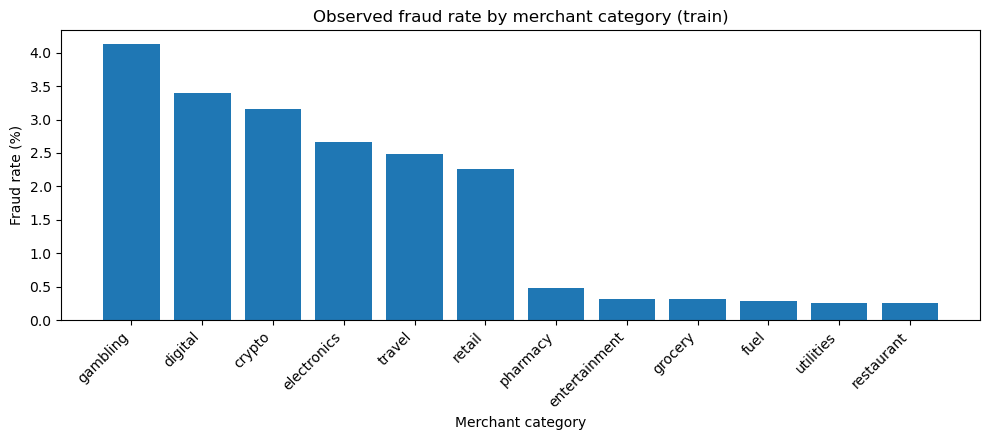

In [8]:
category_risk = (
    train.groupby("merchant_category")["is_fraud"]
    .agg(fraud_count="sum", transaction_count="count", fraud_rate="mean")
    .sort_values("fraud_rate", ascending=False)
)
category_risk["fraud_rate_pct"] = 100 * category_risk["fraud_rate"]
display(category_risk[["fraud_count", "transaction_count", "fraud_rate_pct"]].round(2))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(category_risk.index, category_risk["fraud_rate_pct"])
ax.set(title="Observed fraud rate by merchant category (train)", ylabel="Fraud rate (%)", xlabel="Merchant category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 9. Investigate transaction hour

- `.dt.hour` extracts the hour (0–23) from a datetime.
- Fraud rate by hour may help CatBoost discover time-related patterns.
- **Question:** Are night-time transactions unusually risky compared with daytime?

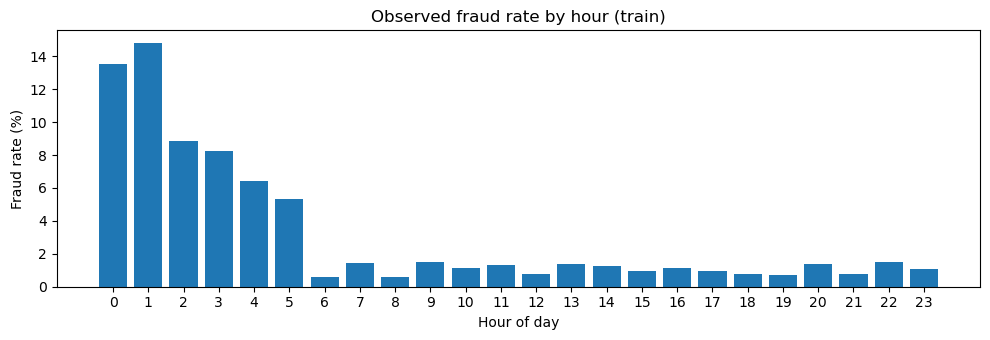

,fraud_count,transaction_count,fraud_rate
is_night,,,
False,625,58192,0.0107
True,174,2005,0.0868


In [9]:
train["transaction_hour"] = train["timestamp"].dt.hour
hourly_risk = train.groupby("transaction_hour")["is_fraud"].agg(
    fraud_count="sum", transaction_count="count", fraud_rate="mean"
)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(hourly_risk.index, 100 * hourly_risk["fraud_rate"])
ax.set(title="Observed fraud rate by hour (train)", xlabel="Hour of day", ylabel="Fraud rate (%)", xticks=range(24))
plt.tight_layout()
plt.show()

train["is_night"] = train["transaction_hour"].between(0, 5)
display(train.groupby("is_night")["is_fraud"].agg(
    fraud_count="sum", transaction_count="count", fraud_rate="mean"
).round(4))

In [12]:
# Extract hour from transaction timestamp
train["transaction_hour"] = train["timestamp"].dt.hour

# Create a night transaction indicator
train["is_night"] = (
    train["transaction_hour"].between(0, 5)
).astype(int)

In [13]:
hourly_summary = (
    train.groupby("transaction_hour")
    .agg(
        total_transactions=("is_fraud", "size"),
        fraud_transactions=("is_fraud", "sum"),
        fraud_rate=("is_fraud", "mean")
    )
    .reset_index()
)

hourly_summary["fraud_rate"] *= 100

display(hourly_summary)

,transaction_hour,total_transactions,fraud_transactions,fraud_rate
0,0,266,36,13.533835
1,1,236,35,14.830508
2,2,248,22,8.870968
3,3,328,27,8.231707
4,4,419,27,6.443914
5,5,508,27,5.314961
6,6,712,4,0.561798
7,7,1112,16,1.438849
8,8,1549,9,0.581020
9,9,2070,31,1.497585


## 10. Amount distribution: do not assume bigger means fraud

- `.describe()` summarizes numerical features.
- `.median()` is often preferable to the mean for skewed transaction amounts.
- `np.log1p(amount)` computes `log(1 + amount)`, which makes strongly right-skewed amounts easier to visualize without changing the original data.

,count,mean,median,maximum
is_fraud,,,,
0,59398,68.93,22.39,25000.0
1,799,57.26,33.05,555.7


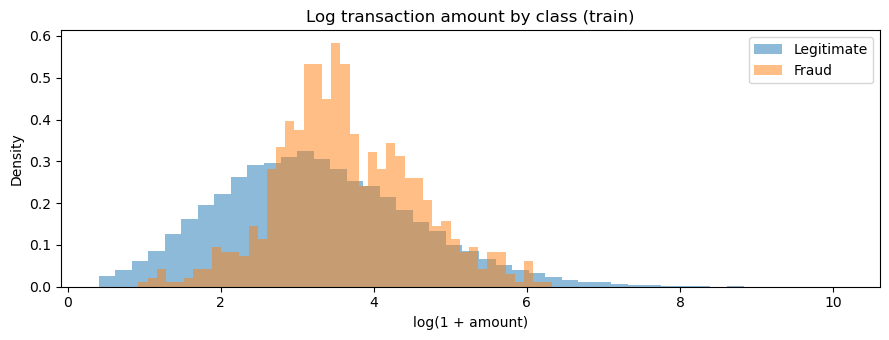

In [10]:
display(train.groupby("is_fraud")["amount"].agg(
    count="count", mean="mean", median="median", maximum="max"
).round(2))

fig, ax = plt.subplots(figsize=(9, 3.5))
for label, name in [(0, "Legitimate"), (1, "Fraud")]:
    amounts = np.log1p(train.loc[train["is_fraud"] == label, "amount"])
    ax.hist(amounts, bins=45, density=True, alpha=0.5, label=name)
ax.set(title="Log transaction amount by class (train)", xlabel="log(1 + amount)", ylabel="Density")
ax.legend()
plt.tight_layout()
plt.show()

## 11. Customer overlap across train and test

Repeated cards make customer-behavior features (median amount, recent frequency, new merchant/device) promising. We compare **ID sets**; no test labels are involved.

In [11]:
train_card_ids = set(train["card_id"])
test_card_ids = set(test["card_id"])
shared_card_ids = train_card_ids & test_card_ids

print("Unique training cards:", len(train_card_ids))
print("Unique test cards:    ", len(test_card_ids))
print("Cards in both:       ", len(shared_card_ids))
print("Share of test-card IDs seen in training:", f"{len(shared_card_ids) / len(test_card_ids):.2%}")

print("Distinct merchants in both sets:", len(set(train["merchant_id"]) & set(test["merchant_id"])))

Unique training cards: 6711
Unique test cards:     6347
Cards in both:        6148
Share of test-card IDs seen in training: 96.86%
Distinct merchants in both sets: 2000


## 12. EDA checklist — answer before training

Write down your findings:

1. How many rows and columns does each CSV contain? Why does the test set have one fewer column?
2. Which feature is missing for around half of the transactions? Is that missingness an error?
3. What is the labeled fraud rate? Why would accuracy be misleading?
4. Does the test set come after training chronologically? What does that mean for validation?
5. Which merchant categories and transaction hours show elevated **observed** fraud rates?
6. Why might **amount divided by a card's typical amount** be better than raw amount?

**Next notebook:** `02_catboost_baseline.ipynb` after we decide which basic features to use. For this project, we will compare models with time-based ROC AUC validation. Do not train on test labels—they do not exist.